In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from pathlib import Path

print("METHANESCOPE AI")
print("Lesson 1.5: Satellite Observation Systems")
print("Scientific environment ready!")

METHANESCOPE AI
Lesson 1.5: Satellite Observation Systems
Scientific environment ready!


In [2]:
#Simulate Emitting facility


In [3]:
# Seven days of hourly observations
times = pd.date_range(
    "2026-01-01",
    periods=7 * 24,
    freq="h",
    tz="UTC"
)

# Initially, the facility is not emitting
emitting = np.zeros(len(times), dtype=bool)

# Define four separate methane emission episodes
# Each tuple represents [start_hour, end_hour)
episodes = [
    (10, 18),
    (36, 41),
    (70, 82),
    (131, 137)
]

for start, end in episodes:
    emitting[start:end] = True

# Calculate the true simulated active fraction
true_fraction = emitting.mean()

print("Total hours:", len(times))
print("Hours emitting:", emitting.sum())
print("True active fraction:", round(true_fraction, 4))

Total hours: 168
Hours emitting: 31
True active fraction: 0.1845


In [4]:
#Generate Satelite observations


In [5]:
# Define three hypothetical observation schedules
strategies = {
    "Daily at 11:00": times.hour == 11,
    "Every 6 hours": times.hour.isin([2, 8, 14, 20]),
    "Hourly": np.ones(len(times), dtype=bool)
}

# Reproducible random generator
rng = np.random.default_rng(12)

# Simplified sensor and observation conditions
valid_probability = 0.80
detection_probability = 0.90

summary_rows = []
observation_rows = []

for name, schedule in strategies.items():

    indices = np.flatnonzero(schedule)

    # Not every scheduled observation is valid
    valid = (
        rng.random(len(indices)) < valid_probability
    )

    # Only valid observations can detect emissions
    detected = (
        emitting[indices]
        & valid
        & (
            rng.random(len(indices))
            < detection_probability
        )
    )

    valid_count = int(valid.sum())
    detection_count = int(detected.sum())

    # Observed detection fraction
    observed_fraction = (
        detection_count / valid_count
        if valid_count > 0
        else np.nan
    )

    summary_rows.append({
        "Strategy": name,
        "Scheduled": len(indices),
        "Valid": valid_count,
        "Detections": detection_count,
        "Observed Fraction": observed_fraction
    })

    # Save individual observation records
    for k, hour_index in enumerate(indices):
        observation_rows.append({
            "timestamp": times[hour_index],
            "strategy": name,
            "valid": bool(valid[k]),
            "detected": bool(detected[k]),
            "actually_emitting": bool(
                emitting[hour_index]
            )
        })

summary = pd.DataFrame(summary_rows)

observations = pd.DataFrame(observation_rows)

print(
    "True active fraction:",
    round(true_fraction, 4)
)

print("\nSatellite observation comparison:")
print(summary.to_string(index=False))

True active fraction: 0.1845

Satellite observation comparison:
      Strategy  Scheduled  Valid  Detections  Observed Fraction
Daily at 11:00          7      6           2           0.333333
 Every 6 hours         28     21           2           0.095238
        Hourly        168    133          20           0.150376


In [6]:
#plot emission history

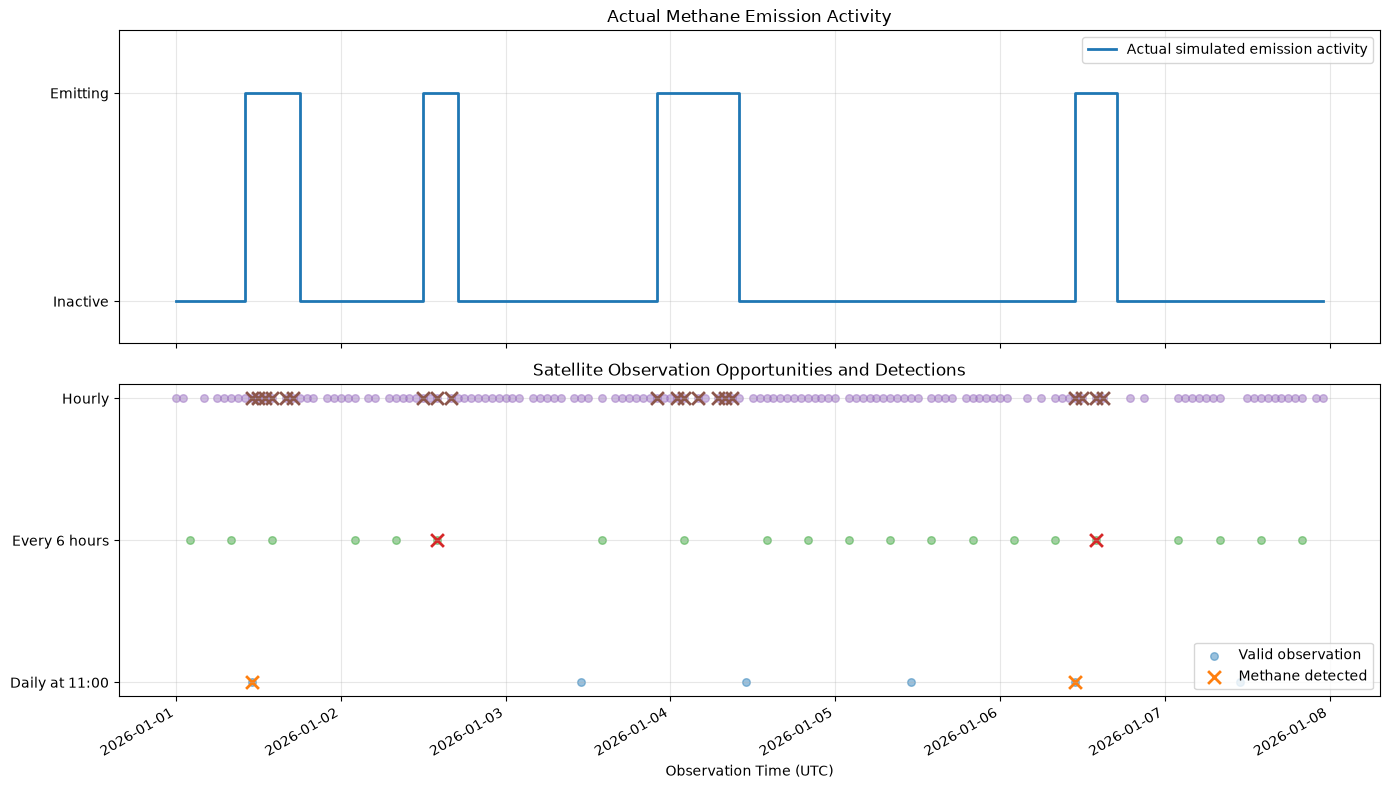

In [7]:
fig, axes = plt.subplots(
    2, 1,
    figsize=(14, 8),
    sharex=True
)

# Plot the true methane emission activity
axes[0].step(
    times,
    emitting.astype(int),
    where="post",
    linewidth=2,
    label="Actual simulated emission activity"
)

axes[0].set_yticks([0, 1])
axes[0].set_yticklabels(["Inactive", "Emitting"])
axes[0].set_ylim(-0.2, 1.3)
axes[0].set_title("Actual Methane Emission Activity")
axes[0].grid(alpha=0.3)
axes[0].legend()

# Plot each observation schedule
for i, name in enumerate(strategies):

    subset = observations[
        (observations["strategy"] == name)
        & observations["valid"]
    ]

    detections = subset[subset["detected"]]

    # All valid observation opportunities
    axes[1].scatter(
        subset["timestamp"],
        np.full(len(subset), i),
        marker="o",
        alpha=0.45,
        s=30,
        label="Valid observation" if i == 0 else None
    )

    # Observations where methane was detected
    axes[1].scatter(
        detections["timestamp"],
        np.full(len(detections), i),
        marker="x",
        s=85,
        linewidths=2,
        label="Methane detected" if i == 0 else None
    )

axes[1].set_yticks(range(len(strategies)))
axes[1].set_yticklabels(list(strategies))

axes[1].set_title(
    "Satellite Observation Opportunities and Detections"
)

axes[1].set_xlabel("Observation Time (UTC)")
axes[1].grid(alpha=0.3)
axes[1].legend()

fig.autofmt_xdate()
plt.tight_layout()
plt.show()

In [8]:
#Export Data

In [9]:
# Create output directory
output_dir = Path("outputs")
output_dir.mkdir(exist_ok=True)

# Save individual satellite observations
observations.to_csv(
    output_dir / "satellite_observations.csv",
    index=False
)

# Save comparison results
summary.to_csv(
    output_dir / "observation_comparison.csv",
    index=False
)

print("Datasets exported successfully!")
print("Location:", output_dir.resolve())

Datasets exported successfully!
Location: C:\Users\SOOQ ELASER\OneDrive\Desktop\RemoteSensing\MethaneScope\outputs
